# Motivation and intention

This is a reproduction of Silverman (2019) on more data, with different dimensions, and trained on Li-Packard classes.

The rest of the architecture is as similar as possible.

**Important differences**:
- ...

**Questions**
- Is the dataset really completely accurate? Looking at the misclassified diagrams, five out of the seven 'wrong' classifications are in fact correct, I think.

**Remarks**
- We are currently in the accuracy regime where every hit or miss in the data set is clearly visible in the curves. We could generate even more data, but I think we can conclude that our accuracy is sufficient.
- ...

# Loading packages and functions

In [1]:
# !pip install cellpylib
# import cellpylib as cpl

# TensorFlow and tf.keras
import tensorflow as tf
from tensorflow import keras

print(tf.__version__)

# Helper libraries
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk
import pandas as pd
import os
import json

# fix random seed for reproducibility
seed = 2023
np.random.seed(seed)

from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, BatchNormalization, Activation
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalMaxPooling2D
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import load_model
from tensorflow.keras import Input

2.15.0


In [2]:
# uncomment if you want to use Drive

from google.colab import drive
drive.mount('/content/gdrive')

images_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Images'
models_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Models'
files_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Files'
# !ls '/content/gdrive/My Drive/'

Mounted at /content/gdrive


In [3]:
# Load function to show accuracy and loss history

def plot_history(history, steps_per_epoch = 0, y_axis_bounds = None, show_val=True, show_loss=True):

    if steps_per_epoch >0:
        xvals = int(steps_per_epoch)*np.array(history.epoch)
        xlab = 'Weight update steps'
    else:
        xvals = np.array(history.epoch)
        xlab = 'Epochs'

    if show_loss:
      plt.figure(figsize = (12,4))
      plt.subplot(1,2,1)
    else:
      plt.figure(figsize= (6,4))
    plt.xlabel(xlab)
    plt.ylabel('Accuracy')
    plt.plot(xvals, np.array(history.history['accuracy']),'g-',
             label='Train accuracy')
    if show_val:
      plt.plot(xvals, np.array(history.history['val_accuracy']),'r-',
             label = 'Validation accuracy')
    if y_axis_bounds:
        plt.ylim(y_axis_bounds)
    plt.legend()

    if show_loss:
      plt.subplot(1,2,2)
      plt.xlabel(xlab)
      plt.ylabel('Loss minimised by model')
      plt.plot(xvals, np.array(history.history['loss']),'g-',
              label='Train loss')
      if show_val:
        plt.plot(xvals, np.array(history.history['val_loss']),'r-',
              label = 'Validation loss')
    plt.legend()

In [4]:
# Load function to translate rule to Li-Packard classes (for loading/showing data)
# Note: This function is very poorly designed (slow)

def whichClass(dictionary, rules, class_to_num=None):
    keys = []
    for i, rule in enumerate(rules):
      for key, array in dictionary.items():
          if np.isin(rule, array):
            if class_to_num: # digits rather than strings
              keys.append(class_to_num[key])
            else: # strings rather than digits
              keys.append(key)
    return np.array(keys)

# Loading and showing data

In [34]:
OUTPUT_TYPE = 'classes' # choose between 'rules', 'independent', 'classes'

# Choose validation set fraction
val_frac = 1/4

# give the right names for the files we will import. Training set
train_name_prefix = "ECAs_1024sims-per-rule_64x64"
train_diagram_name = train_name_prefix + "_train_diagrams.npy"
if OUTPUT_TYPE == 'rules':
  train_name_suffix = "_train_labels.npy"
elif OUTPUT_TYPE == 'independent':
  train_name_suffix = "_train_labels_indep.npy"
elif OUTPUT_TYPE == 'classes':
  train_name_suffix = "_train_labels_class.npy"
train_label_name = train_name_prefix + train_name_suffix

# give the right names for the files we will import. Test set
test_name_prefix = "ECAs_128sims-per-rule_64x64"
test_diagram_name = test_name_prefix + "_test_diagrams.npy"
if OUTPUT_TYPE == 'rules':
  test_name_suffix = "_test_labels.npy"
elif OUTPUT_TYPE == 'independent':
  test_name_suffix = "_test_labels_indep.npy"
elif OUTPUT_TYPE == 'classes':
  test_name_suffix = "_test_labels_class.npy"
test_label_name = test_name_prefix + test_name_suffix

# Load the data. Training set
x_train_all = np.load(f"{files_dir}/{train_diagram_name}")
r_train_all = np.load(f"{files_dir}/{train_label_name}")

# Load the data. Test set
x_test_all = np.load(f"{files_dir}/{test_diagram_name}")
r_test_all = np.load(f"{files_dir}/{test_label_name}")

# take examples from the data set to show below
rules_example = np.array([168, 232, 178, 154, 161]) # final rules in table of Li-Packard
indices_example = int(x_train_all.shape[0]/256)*rules_example
x_train_example = np.take(x_train_all, indices_example, axis=0)
r_train_example = np.take(r_train_all, indices_example, axis=0)

# Shuffle test data at random, keeping the relation between diagrams and labels
shuffle_indices = np.random.permutation(range(r_train_all.shape[0]), )
x_train_all = x_train_all[shuffle_indices]
r_train_all = r_train_all[shuffle_indices]

# Split training data in a training and validation set
val_size = int(x_train_all.shape[0]*val_frac)
x_train, x_val, r_train, r_val = train_test_split(x_train_all, r_train_all, test_size=val_size, random_state=0, shuffle=True, stratify=r_train_all)

# Translate rule to Li-Packard class
with open(f"{files_dir}/all_Li-Packard_dict.json", "r") as fp:
    # Load the dictionary from the file
    Li_Packard_dict = json.load(fp)

with open(f"{files_dir}/equiv_ECA_rules.json", "r") as fp:
    # Load the dictionary from the file
    equiv_ECA_rules = json.load(fp)

# Change key names to digits
class_to_num = dict({'null':0, 'fixed point':1, 'periodic':2, 'locally chaotic':3, 'chaotic':4})
num_to_class = dict({0:'null', 1:'fixed point', 2:'periodic', 3:'locally chaotic', 4:'chaotic'})

# Change key names to digits
indep_to_num = dict({indep:digit for indep, digit in zip(equiv_ECA_rules, range(len(equiv_ECA_rules)))})
num_to_indep = dict({digit:indep for indep, digit in indep_to_num.items()})

# Translate to one-hot vectors for cross entropy loss function
r_train = keras.utils.to_categorical(r_train)
r_val = keras.utils.to_categorical(r_val)

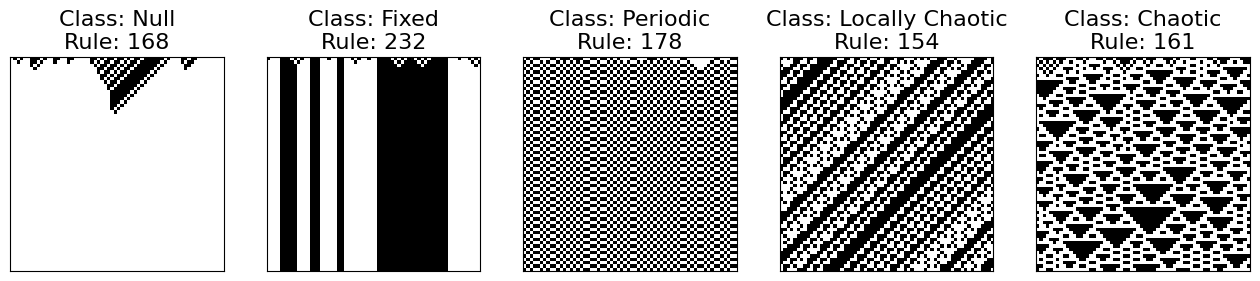

In [ ]:
# Generate examples from every class (chosen deterministically earlier)
SAVEFIG=False
SAVENAME="LP-classes-examples.pdf"

figsize=16
title_size=16
fig, axs = plt.subplots(1,5, figsize=(figsize, 5*figsize))
LP_classes_example = ["Null","Fixed","Periodic","Locally Chaotic","Chaotic"]
for i in range(5):
  class_rule = r_train_example[i,0]
  class_name = LP_classes_example[i]
  axs[i].imshow(x_train_example[i, :, :, 0], cmap='Greys')
  axs[i].set_title(f"Class: {class_name}\nRule: {class_rule}", size=title_size)
  axs[i].set_xticks([])
  axs[i].set_yticks([])

if SAVEFIG:
  plt.savefig(f'{images_dir}/{SAVENAME}', bbox_inches='tight')

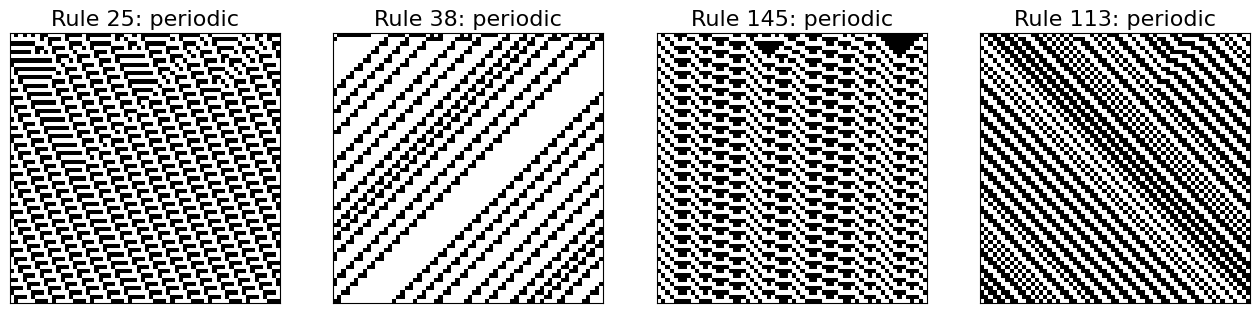

In [ ]:
# Generate a couple of examples to verify that data loading went well

number_of_examples = 4
examples_from = 'train' # train, val or test
if examples_from == 'train':
  diagrams = x_train
  labels = r_train5
  rules = r_train_rule
elif examples_from == 'val':
  diagrams = x_val
  labels = r_val5
  rules = r_val_rule
elif examples_from == 'test':
  diagrams = x_test_all
  labels = r_test5_all
  rules = r_test_rule_all
else:
  raise Exception("Choose between 'train', 'val' or 'test'.")

examples_indices = np.random.randint(0,diagrams.shape[0],number_of_examples)

figsize=16
title_size=16
fig, axs = plt.subplots(1,number_of_examples, figsize=(figsize, number_of_examples*figsize))
for i, ex in enumerate(examples_indices):
  class_rule = rules[ex][0]
  class_code = np.nonzero(labels[ex])[0][0]
  class_name = num_to_class[class_code]
  axs[i].imshow(diagrams[ex, :, :, 0], cmap='Greys')
  axs[i].set_title(f"Rule {class_rule}: {class_name}", size=title_size)
  axs[i].set_xticks([])
  axs[i].set_yticks([])

# Designing and running the convolutional neural network

In [ ]:
def silverman_model(diagram_dims=(60, 120, 1), conv_kernel_dims=(2, 3), dilation_rate=(1,1), output_type='classes'):
    # output_type param should be 'classes' or 'rules'

    # tell the model which input shape the samples will have
    inputs = Input(diagram_dims, dtype=tf.float32)

    # Conv block, width = 16
    x = Conv2D(16, conv_kernel_dims, padding='valid', dilation_rate=dilation_rate)(inputs)
    x = Activation('relu')(x)
    x = Conv2D(16, conv_kernel_dims, padding='valid')(x)
    x = Activation('relu')(x)
    x = GlobalMaxPooling2D()(x)
    x = Flatten()(x)
    # and finally the linear classification output layer
    if output_type=='classes':
      x = Dense(256)(x)
      output = Dense(5, activation="softmax")(x)
    elif output_type=='rules':
      output = Dense(256, activation="softmax")(x)
    else:
      raise Exception("Parameter 'output_type' should be either 'classes' (5-fold) or 'rules' (256-fold).")
    model = tf.keras.Model(inputs=inputs, outputs=output)

    # Note that, in contrast to the first graded assignment,
    # we have taken the model compilation out of this function (it is done in the model training block)

    return model

In [13]:
RUN_AGAIN = False
SAVE_AGAIN = False
model_name_rules = "reproducing_silverman2019_default64x64_rules"
model_name = "reproducing_silverman2019_default64x64"
conv_kernel_dims = (2, 3)
dilation_rate = (1,1)

diagram_dims = (64,64,1)

# Conv kernel sketching board
# 1 0 0 1 0 0 1 0 0 1
# 0 0 0 0 0 0 0 0 0 0
# 1 0 0 1 0 0 1 0 0 1

if RUN_AGAIN:
  N_train = x_train.shape[0]
  batch_size = 64
  batches_per_epoch = int(N_train/batch_size)
  epochs = 50
  LR = 0.001
  stopping_patience = 5
  stopping_delta = 0.00001

  model_default = silverman_model(diagram_dims=diagram_dims, conv_kernel_dims=conv_kernel_dims, dilation_rate=dilation_rate, output_type=OUTPUT_TYPE)
  model_default.summary()

  model_default.compile(loss='categorical_crossentropy',
                  optimizer=Adam(learning_rate=LR),
                  metrics=['accuracy'])

  stopping_callback = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy',
                                                      patience=stopping_patience,
                                                      min_delta=stopping_delta,
                                                      verbose = 1,
                                                      restore_best_weights=True)

  history_default = model_default.fit(x_train,
                          r_train,
                          batch_size=batch_size,
                          epochs=epochs,
                          verbose=1,
                          validation_data=(x_val, r_val),
                          shuffle=True,
                          callbacks = [stopping_callback])

  if SAVE_AGAIN:
    model_default.save(f"{models_dir}/{model_name}")

else:
  model_default_rules = load_model(f"{models_dir}/{model_name_rules}")
  model_default = load_model(f"{models_dir}/{model_name}")

In [ ]:
CALCULATE_AGAIN = True
SAVE_FIG = False

if CALCULATE_AGAIN:
  [train_loss, train_accuracy] = model_default_rules.evaluate(x_train, r_train, verbose=1)
  [val_loss, val_accuracy] = model_default_rules.evaluate(x_val, r_val, verbose=1)

print("Training set Accuracy:{:7.6f}".format(train_accuracy))
print("Training set Loss:{:7.6f}\n".format(train_loss))

print("Validation set Accuracy:{:7.6f}".format(val_accuracy))
print("Validation set Loss:{:7.6f}\n".format(val_loss))

if RUN_AGAIN:
  #Now we visualise what happened during training
  plot_history(history_default, y_axis_bounds=[0.95,1], show_loss=False)
  plt.title(f'Class identification: {round(100*val_accuracy,2)}% val. accuracy', size=16)

  if SAVE_FIG:
    plt.savefig(f'{images_dir}/accuracy-hist_{model_name}.pdf', bbox_inches='tight')

2048/2048 [==============================] - 6s 3ms/step - loss: 0.0052 - accuracy: 0.9985
Training set Accuracy:0.998530
Training set Loss:0.004859

Validation set Accuracy:0.998520
Validation set Loss:0.005160



# Analysis of the model performance

In [ ]:
# inspect values of penultimate nodes for the class inference model
CALCULATE_AGAIN = True

if CALCULATE_AGAIN:
  hidden_layer_model = tf.keras.Model(inputs=model_default.input, outputs=model_default.layers[-2].output)
  hidden_layer_values = hidden_layer_model.predict(x_train)

# perform linear regression between rule value and hidden-layer value

# import packages
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Linear regression fit
model = LinearRegression()
model.fit(hidden_layer_values,r_train_rule[:,0])

# predict and compare with actual results
r_train_rule_pred = model.predict(hidden_layer_values)
mse = mean_squared_error(r_train_rule[:,0], r_train_rule_pred)
r_squared = r2_score(r_train_rule[:,0], r_train_rule_pred)

print(f"Fitting the final hidden layer to the ECA rule gives an R2 value of {round(r_squared,2)}.")
zz
# IMPORTANT NOTE: THERE IS A VERY OBVIOUS CORRELATION BETWEEN THE RULE AND THE CLASS,
# AND THE CLASS IS CERTAINLY IN SOME SENSE ENCODED IN THE FINAL HIDDEN LAYER
# SO A CORRELATION WITH THE HIDDEN LAYER AND THE RULE IS DEFINITELY GOING TO BE THERE

# IMPORT NOTE: LINEAR REGRESSION MAY NOT BE THE WAY TO GO, BECAUSE THE MAPPING BETWEEN
# ECA RULE AND NODE VECTOR IS NOT NECESSARILY MONOTONIC

-0.0011927400225260065


2048/2048 [==============================] - 51s 25ms/step


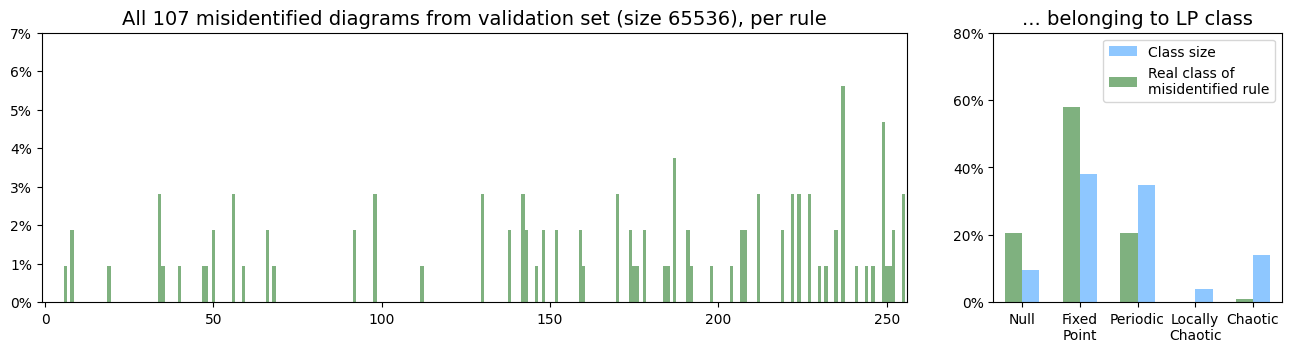

In [8]:
SAVEFIG=True
SAVENAME='default-model_misidentified-val-set.pdf'

# the predictions are class probabilities,
# the argmax code line below finds the index of the class with the highest probability
predictions_rules = model_default_rules.predict(x_val)
# predictions_classes = model_default.predict(x_val)

val_predicted_rule = np.argmax(predictions_rules,axis=1)
val_real_rule = np.argmax(r_val,axis=1)
# val_predicted_class = np.argmax(predictions_classes, axis=1)

ugent_blue = (30/255,100/255,200/255)
ugent_yellow = (255/255, 210/255, 0/255)

color1 = 'maroon'
color2 = 'darkgreen'
prevalence_color = 'dodgerblue'

misclassified_rules_idxs, = np.where(val_predicted_rule!=val_real_rule)
misclassified_rules_guess = val_predicted_rule[misclassified_rules_idxs]
misclassified_rules_real = val_real_rule[misclassified_rules_idxs]

# misclassified_classes_idxs, = np.where(val_predicted_class!=r_val_class[:,0]) # too much RAM!
# misclassified_classes_real = r_val_class[misclassified_classes_idxs,0]
# misclassified_classes_guess = val_predicted_class[misclassified_classes_idxs]

misclassified_rules_sizes_guess = np.array([np.count_nonzero(misclassified_rules_guess==i) for i in range(256)])
misclassified_rules_sizes_real = np.array([np.count_nonzero(misclassified_rules_real==i) for i in range(256)])

misclassified_rules_asclass_real = whichClass(Li_Packard_dict, misclassified_rules_real, class_to_num=class_to_num)
misclassified_rules_asclass_sizes_real = np.array([np.count_nonzero(misclassified_rules_asclass_real==i) for i in range(5)])

# misclassified_classes_sizes_real = np.array([np.count_nonzero(misclassified_classes_real==i) for i in range(5)])
# misclassified_classes_sizes_guess = np.array([np.count_nonzero(misclassified_classes_guess==i) for i in range(5)])

fig, axs = plt.subplots(1,2,figsize=(16,3.5), width_ratios=(3,1))
plt.subplots_adjust(wspace=0.15)
labelsize=12

axs[0].bar(np.arange(256), misclassified_rules_sizes_real / sum(misclassified_rules_sizes_real), width=1,
       color=color2, alpha=.5,
       label='Real rule of misidentified diagram')
# ax.bar(np.arange(256)+0.25, misclassified_rules_sizes_guess / sum(misclassified_rules_sizes_guess), width=0.5,
#        color=color2, alpha=.5,
#        label='Inferred rule of misidentified diagram')

# add prevalence of every LP class
width=0.3
bar_offset=width/2
class_prevalences = []
for key, item in Li_Packard_dict.items():
  class_prevalence = len(item) / 256
  class_prevalences.append(class_prevalence)
axs[1].bar(np.arange(5)+bar_offset, class_prevalences, width=width, color=prevalence_color, alpha=0.5, label='Class size')

# add which class the wrongly identified rule belongs to
axs[1].bar(np.arange(5)-bar_offset, misclassified_rules_asclass_sizes_real / sum(misclassified_rules_asclass_sizes_real), width=width,
       color=color2, alpha=.5,
       label='Real class of\nmisidentified rule')
# ax.bar(np.arange(256)+0.25, misclassified_classes_sizes_guess / sum(misclassified_classes_sizes_guess), width=0.5,
#        color=color2, alpha=.5,
#        label='Inferred rule of misidentified diagram')

axs[0].set_xlim([-1,256])
axs[0].set_ylim([0, 0.07])
axs[0].set_yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07])
axs[0].set_yticklabels(['0%', '1%', '2%', '3%', '4%', '5%', '6%', '7%'])
# axs[0].set_xticklabels(num_to_class.keys(), size=labelsize)

axs[1].set_ylim([0, .8])
axs[1].set_yticks([0, 0.2, 0.4, 0.6, 0.8])
axs[1].set_yticklabels(['0%', '20%', '40%', '60%', '80%'])

axs[1].set_xlim([-.5,4.5])
axs[1].set_xticks([0, 1, 2, 3, 4])
xticklabels=['Null','Fixed\nPoint', 'Periodic','Locally\nChaotic','Chaotic']
axs[1].set_xticklabels(xticklabels)
# axs[1].set_ylim([0, 0.07])
# axs[1].set_yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07])
# axs[1].set_yticklabels(['0%', '1%', '2%', '3%', '4%', '5%', '6%', '7%'])
# axs[1].set_xticklabels(num_to_class.keys(), size=labelsize)

axs[0].set_title(f"All {len(misclassified_rules_idxs)} misidentified diagrams from validation set (size {r_val.shape[0]}), per rule", fontsize=labelsize+2)
axs[1].set_title(f"... belonging to LP class", fontsize=labelsize+2)
axs[1].legend(prop={'size':labelsize-2})

if SAVEFIG:
  plt.savefig(f'{images_dir}/{SAVENAME}', bbox_inches='tight')

In [35]:
# the predictions are class probabilities,
# the argmax code line below finds the index of the class with the highest probability
predictions_classes = model_default.predict(x_val)
val_predicted_class = np.argmax(predictions_classes, axis=1).astype(np.int8)
val_real_class = np.argmax(r_val,axis=1).astype(np.int8)

2048/2048 [==============================] - 53s 26ms/step


In [39]:
misclassified_idx, = (val_predicted_class!=val_real_class).nonzero()
type(misclassified_idx[0])

numpy.int64

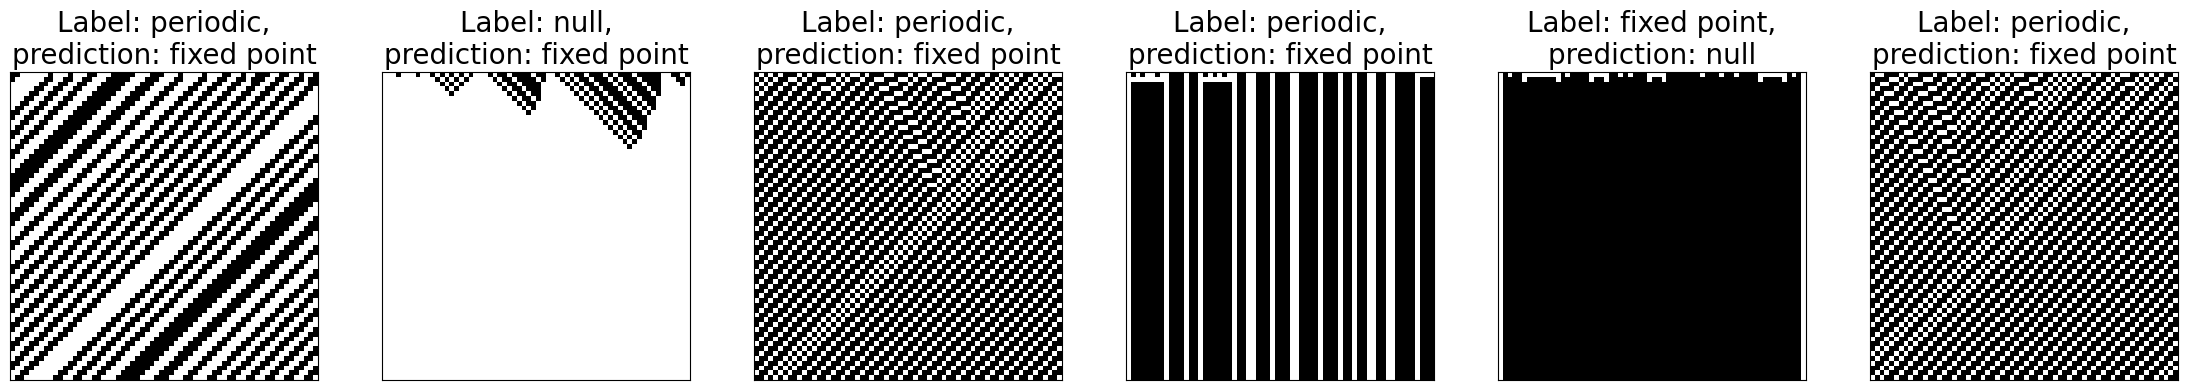

In [44]:
# Show which diagram has been classified wrongly

fix, axs = plt.subplots(1, 6, figsize=(28, 4))

for i in range(6):
  actual_class = num_to_class[val_real_class[misclassified_idx[i]]]
  predicted_class = num_to_class[val_predicted_class[misclassified_idx[i]]]
  axs[i].set_title("Label: " + actual_class
          + ",\nprediction: " + predicted_class, size=20)
  axs[i].imshow(x_val[misclassified_idx[i],:,:,0], cmap='Greys', interpolation='None')
  axs[i].set_xticks([])
  axs[i].set_yticks([])

plt.savefig(f"{images_dir}/default-model_all-wrong-LP-classes.pdf", bbox_inches='tight')

Note how the "misclassified" periodic diagrams are often quite logical.